# W03: Dane psychologiczne i ich reprezentacja

**Wersja źródła:** 1.0.7 · **Data:** 2026-11-03

Dane syntetyczne: 36 osób, 14 dni;

In [1]:
from pathlib import Path
from math import sin, cos
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
print(pd.__version__, np.__version__)


3.1.1 2.5.4


## Dane
Jeśli nie ma pliku CSV, notebook generuje identyczne, deterministyczne dane. Braki częściowo zależą od wartości stresu.

In [2]:
def generuj():
    rows = []
    for osoba in range(1, 37):
        for dzien in range(1, 15):
            sen = round(7.3 + 0.45 * sin(osoba * .9) + .7 * sin(dzien * 1.2 + osoba), 2)
            stres = round(max(0, min(10, 5.2 - .5 * (sen - 7.3)
                         + .8 * sin(osoba * .47) + .4 * cos(dzien * .9 + osoba))), 1)
            nastroj = round(max(0, min(10, 7.1 - .53 * stres
                           + .15 * sin(osoba * .7 + dzien))), 1)
            brak = (stres >= 6 and (osoba + dzien) % 3 == 0) or (
                (osoba * 7 + dzien * 11) % 37 == 0)
            rows.append([osoba, dzien, sen, np.nan if brak else stres, nastroj])
    return pd.DataFrame(rows, columns=["osoba", "dzien", "sen_h", "stres", "nastroj"])

plik = Path("pi_w03_data.csv")
dane = pd.read_csv(plik) if plik.exists() else generuj()
assert len(dane) == 504
print(dane.head())


   osoba  dzien  sen_h  stres  nastroj
0      1      1   8.22    5.0      4.6
1      1      2   7.47    5.1      4.5
2      1      3   6.96    5.4      4.2
3      1      4   7.33    5.5      4.0
4      1      5   8.11    5.4      4.2


## Kontrola jakości i format długi
Sprawdź unikalność jednostki (osoba, dzień) i zakres samooceny.

In [3]:
assert not dane.duplicated(["osoba", "dzien"]).any()
assert dane.stres.dropna().between(0, 10).all()
assert dane.nastroj.between(0, 10).all()
print("Braki stresu:", dane.stres.isna().sum())
print(dane.groupby("osoba").stres.apply(lambda x: x.isna().sum()).describe())
long = dane.melt(id_vars=["osoba", "dzien"], value_vars=["stres", "nastroj"],
                 var_name="zmienna", value_name="wynik")
assert len(long) == 1008
print(long.head())


Braki stresu: 43
count    36.000000
mean      1.194444
std       0.920231
min       0.000000
25%       0.750000
50%       1.000000
75%       2.000000
max       3.000000
Name: stres, dtype: float64
   osoba  dzien zmienna  wynik
0      1      1   stres    5.0
1      1      2   stres    5.1
2      1      3   stres    5.4
3      1      4   stres    5.5
4      1      5   stres    5.4


## Przebieg w czasie
Rysujemy poziom stresu i nastroju jednej osoby bez wypełniania braków.

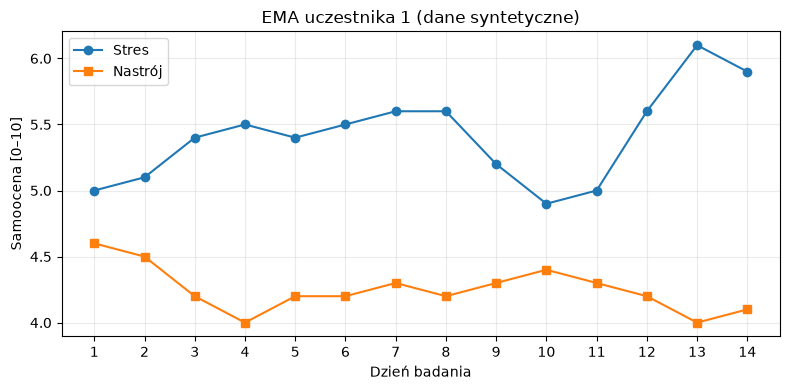

In [4]:
osoba1 = dane.loc[dane.osoba == 1].sort_values("dzien")
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(osoba1.dzien, osoba1.stres, "o-", label="Stres")
ax.plot(osoba1.dzien, osoba1.nastroj, "s-", label="Nastrój")
ax.set(xlabel="Dzień badania", ylabel="Samoocena [0–10]",
       title="EMA uczestnika 1 (dane syntetyczne)")
ax.set_xticks(np.arange(1, 15))
ax.legend()
ax.grid(alpha=.25)
fig.tight_layout()
plt.show()


## Wnioskowanie
Nie traktuj wielu wierszy jednego uczestnika jako wielu niezależnych osób.

In [5]:
osoby = dane.groupby("osoba").agg(
    n_stres=("stres", "count"), sredni_stres=("stres", "mean"),
    sredni_sen=("sen_h", "mean"))
print(osoby.round(2).head())
assert len(osoby) == 36


       n_stres  sredni_stres  sredni_sen
osoba                                   
1           14          5.41        7.61
2           13          5.62        7.66
3           12          5.85        7.45
4           11          5.97        7.13
5           12          5.87        6.94
